In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#1) Read the data from your individual variant into the Python notebook.
data = pd.read_excel("10_Student_Performance.xlsx")

In [ ]:
#2) Output the main information (number of variables, number of instances).
data.info()
data.shape

In [ ]:
#3) Output several first rows of the dataset.
data.head()

In [ ]:
#4) Make explanatory data analyses for each variable (mean, std, etc.).
data.describe(include='all')

In [ ]:
#5) Look at the independent and dependent variables. Divide the dataset accordingly into matrices X and Y.
# Output the shapes of these matrices.
# => We will convert the 'G3' from a numerical to binary 'pass/fail' (pass when G3 >= 10 and fail when G3 < 10)

data['Class'] = np.where(data.G3 >= 10, 'Pass', 'Fail')
Y = data.Class
X = data.drop(['Class', 'G3'], axis=1)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Number of unique classes:", Y.nunique())
Y.value_counts()

In [ ]:
# 6) Look at data types of the variables. Are there any categorical variable you need to encode? Execute
# necessary transformations. Drop some columns if necessary, when recommended in your individual
# variant or the variables are not suitable for the prediction (e.g., Ids, person names).

# => we can easily encode the binary variables such as 'school', 'sex', 'adress' and so on, 
# and also the nominal variables, and we created 2 new variables from G1 and G2 that represent
# the average and the change between the two then we dropped them to avoid multicollinearity.

X['G_Avg'] = (X.G1 + X.G2) / 2
X['Grade_Change'] = X.G2 - X.G1
X = X.drop(['G1','G2'], axis=1)
le = LabelEncoder()
Y_encoded = le.fit_transform(Y)

X_encoded = pd.get_dummies(X,drop_first=True, dtype=int)
X_encoded.info()

In [ ]:
# 7) Are there any Nan values? Try different filling of them (mean, median).
X_encoded.isnull().sum().sum()

In [ ]:
# 8) Check the dependences between each of the independent variable and the target variable and among
# the independent variables. Output correlation table and corresponding heatmap results.

corr_data = X_encoded.copy()
corr_data['Target_Class'] = Y_encoded

corr_table = corr_data.corr()
display(corr_table)
plt.figure(figsize=(20, 15))
sns.heatmap(corr_table, annot=False, cmap='coolwarm')
plt.show()

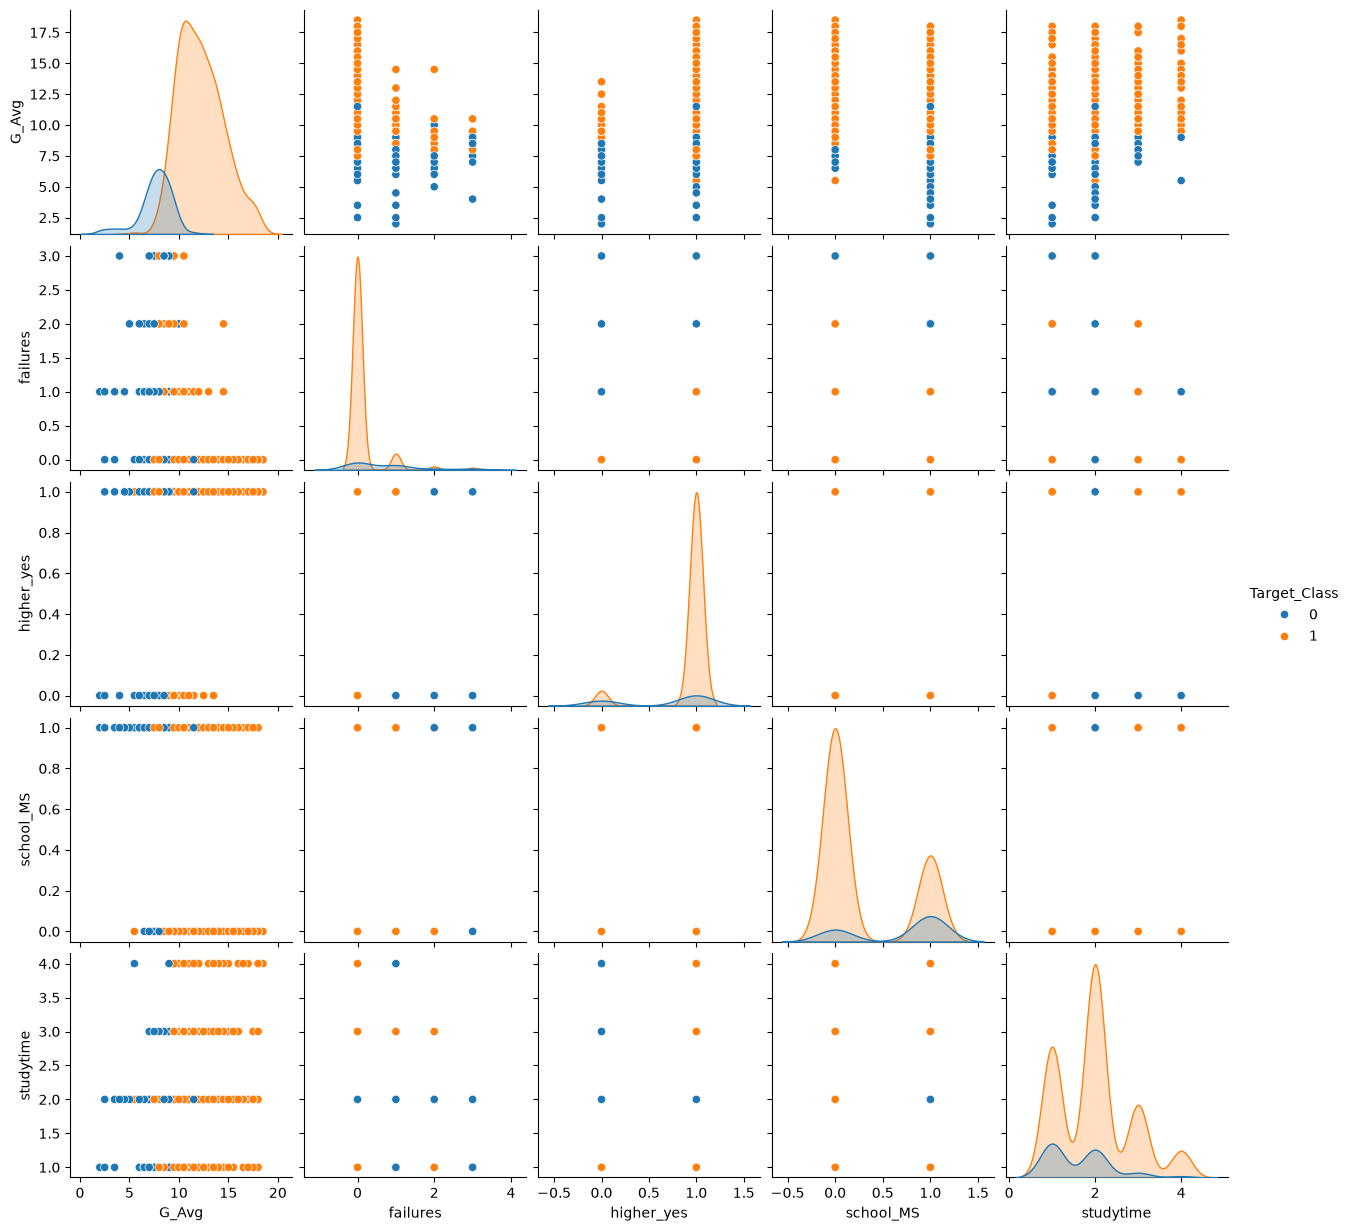

In [62]:
#9) Build 2D plots of dependences between each pair of the variables. Which conclusion can you make?
list_variables = corr_table['Target_Class'].abs().nlargest(6).index
sns.pairplot(corr_data[list_variables], hue='Target_Class')
plt.show()

In [ ]:
# Conclusions : 
# - G_Avg is the strongest separator between classes, with failing students (class 0) concentrated 
# below 10 and passing students (class 1) above 10.
# - Students with higher studytime and plans for higher education (higher_yes = 1) achieve higher 
# G_Avg scores and predominantly pass, while students with multiple past failures cluster at lower G_Avg values and fail.